<p><a href="https://query.farm/"><img src="https://raw.githubusercontent.com/Query-farm/vgi-example-notebooks/v0.1.1/assets/query-farm-strata-sun.svg" alt="Query.Farm — Strata Sun" width="252"></a></p>

<p><a href="https://query.farm/vgi/"><img src="https://raw.githubusercontent.com/Query-farm/vgi-example-notebooks/v0.1.1/assets/vgi-logo.png" alt="VGI" width="112"></a></p>

# [National Weather Service](https://github.com/Query-farm/vgi-nws)

Explore US weather alerts, observations, forecast grids, bulletins, and river conditions.

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Query-farm/vgi-nws/blob/main/notebooks/06_overlapping_products_are_not_a_common_score.ipynb)

[Query.Farm](https://query.farm/) · [VGI](https://query.farm/vgi/) · [Example notes](https://github.com/Query-farm/vgi-nws/blob/main/notebooks/README.md)


## 06 · Overlapping products are not a common score

A point can intersect several polygons from several weather products. How do we
retain the individual product meanings instead of inventing one combined risk score?
We discover a service/layer, inspect its field definitions, then compare generic
features with four typed product families on a fixed pair of synthetic sites.

### Choose a site from a fixed comparison

Use **SITE = "inner"**, then try **"edge"**. Both sites and all source polygons are
retrieved on every run. Only the local display selection changes. The inner site lies
inside two nested rectangles per family, while the edge site intersects only the outer
one. Identical teaching geometry across families is intentional; it is not a claim that
real severe, fire, rainfall and winter products share boundaries.

In [1]:
SITE = "inner"  # Experiment: "edge"

### Run independently

Read the saved results on GitHub or choose **Open in Colab** and Run All. The brief
base install preserves compatible preloaded plotting and kernel libraries. Local
publication uses the optional `[runner]` extra. Initial packages, verified companions,
VGI and native worker download need internet. No worker checkout, Bun or source build
is required. Hosted Colab is not tested; a fresh preloaded Python 3.12 notebook-only
execution checks the common setup path. [Detailed setup and provenance](README.md).

In [2]:
import importlib.metadata as packages

installed = {d.metadata["Name"]: d.version for d in packages.distributions()}
if installed.get("vgi-example-notebooks") != "0.3.40":
    %pip install -q "git+https://github.com/Query-farm/vgi-example-notebooks@v0.3.40"
from vgi_notebooks import check_runtime

check_runtime()
if packages.version("vgi-example-notebooks") != "0.3.40":
    raise RuntimeError("Install shared tools 0.3.40, restart, and Run All.")

In [3]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from IPython.display import display
from vgi_notebooks import prepare
from vgi_notebooks.presentation import finish, prose, theme
from vgi_notebooks.session import connect

prepare("nws")
from scenario_source import ScenarioSource

%matplotlib inline
theme()
session = connect(globals())
con = session.connection
assert con.execute("SELECT name FROM duckdb_secrets()").fetchall() == []
assert con.execute("SELECT current_setting('TimeZone')").fetchone()[0] == "UTC"
source = ScenarioSource()
Path("artifacts").mkdir(exist_ok=True)
PROVENANCE = "Source: synthetic NOAA-shaped teaching inputs · 2 January 2026 UTC · not live conditions"

if SITE not in ("inner", "edge"):
    raise ValueError("SITE must be inner or edge")

### Source boundary

Every value in this story is **synthetic**. The real released NWS worker parses
NOAA-shaped documents served only on loopback; all ten upstream roots are scoped to
that local service and unknown requests fail. No real alert, gauge condition or forecast
is represented. Canonical `source_url` values are emitted by the worker even in this
mode: they describe product routes, not proof of a live request. `fetched_at` is the
local read time. The fixture's fixed scenario time is **2026-01-02 12:00 UTC**.

Shared setup uses an empty temporary SQL-secret directory, disables persistence and
JupySQL default connection autoload, and fixes the connection timezone to UTC. No key,
saved secret or account write is involved. Cleanup closes the connection/service and
restores the temporary process environment.

In [4]:
%%sql
INSTALL vgi FROM community;
LOAD vgi;
ATTACH 'nws' (TYPE vgi, LOCATION 'github-auto://Query-farm/vgi-nws@v0.4.0');

,Success


### Inspect the service and layer contract

`map_products` discovers services in a chosen server folder. A layer tells us whether
the appropriate reader is a feature reader; its field definitions describe types and
native codes. The layer ID 101 here is discovered from the synthetic service, not a
production constant to reuse blindly.

The generic reader preserves attribute and geometry JSON. Its positional `compat`
variants accept the same options as JSON, which is useful for client-side correlated
calls. We compare their business rows with the named-option interface. Equivalent
interfaces do not constitute independent source confirmation.

In [5]:
%%sql
CREATE TABLE sites AS SELECT * FROM (VALUES ('inner',38.0293,-78.4767),('edge',36.5,-79.5)) s(site,latitude,longitude);
CREATE TABLE services AS SELECT * FROM nws.main.map_products(server:='vector',folder:='outlooks');
CREATE TABLE layers AS SELECT * FROM nws.main.map_layers('vector:outlooks/SPC_wx_outlks/MapServer');
CREATE TABLE layers_compat AS SELECT * FROM nws.compat.map_layers('vector:outlooks/SPC_wx_outlks/MapServer','{}');
CREATE TABLE fields AS SELECT * FROM nws.main.map_fields('vector:outlooks/SPC_wx_outlks/MapServer',layer_id:=101);
CREATE TABLE fields_compat AS SELECT * FROM nws.compat.map_fields('vector:outlooks/SPC_wx_outlks/MapServer','{"layer_id":101}');
CREATE TABLE generic AS SELECT * FROM nws.main.map_features('vector:outlooks/SPC_wx_outlks/MapServer',101,include_geometry:=true);
CREATE TABLE generic_compat AS SELECT * FROM nws.compat.map_features('vector:outlooks/SPC_wx_outlks/MapServer',101,'{"include_geometry":true}');
CREATE TABLE generic_at AS SELECT s.site,f.* FROM sites s,LATERAL nws.main.map_features_at('vector:outlooks/SPC_wx_outlks/MapServer',101,s.latitude,s.longitude,include_geometry:=true) f;
CREATE TABLE generic_at_compat AS SELECT s.site,f.* FROM sites s,LATERAL nws.compat.map_features_at('vector:outlooks/SPC_wx_outlks/MapServer',101,s.latitude,s.longitude,'{"include_geometry":true}') f;
SELECT product_id,service_type FROM services ORDER BY product_id;
SELECT layer_id,layer_name,geometry_type,reader,description FROM layers;
SELECT field_name,field_type,alias,nullable,domain_json FROM fields ORDER BY field_name;
SELECT object_id,json_extract_string(attributes_json,'$.label') AS native_label,
 source_file_at,ingested_at,geometry_json FROM generic ORDER BY object_id;
SELECT site,count(*) AS intersecting_features FROM generic_at GROUP BY site ORDER BY site;

,site,intersecting_features
0,edge,1
1,inner,2


### Preserve four different product vocabularies

The typed readers expose product-specific fields instead of leaving all interpretation
inside JSON. Severe categorical outlooks return a category/code and may have NULL
probability; fire wind/relative-humidity categories use their own codes. Rainfall
outlooks preserve a risk description, and winter storm severity returns an impact
label and component. A numeric code such as 5 is not a shared score across products.
Missing issue times or probabilities stay missing.

Each family below retrieves its complete synthetic layer, then intersects both sites.
The positional `_at` counterpart uses the same day/period options. We retain every
matching polygon; two nested features are not two independent weather events. The
fixed source, ingestion, issue and validity times also remain separate clocks.

In [6]:
%%sql
CREATE TABLE severe_full AS SELECT * FROM nws.main.severe_outlook(day:=1,include_geometry:=true);
CREATE TABLE severe_at AS SELECT s.site,f.* FROM sites s,LATERAL nws.main.severe_outlook_at(s.latitude,s.longitude,day:=1) f;
CREATE TABLE severe_compat AS SELECT s.site,f.* FROM sites s,LATERAL nws.compat.severe_outlook_at(s.latitude,s.longitude,'{"day":1}') f;
CREATE TABLE fire_full AS SELECT * FROM nws.main.fire_outlook(day:=1,include_geometry:=true);
CREATE TABLE fire_at AS SELECT s.site,f.* FROM sites s,LATERAL nws.main.fire_outlook_at(s.latitude,s.longitude,day:=1) f;
CREATE TABLE fire_compat AS SELECT s.site,f.* FROM sites s,LATERAL nws.compat.fire_outlook_at(s.latitude,s.longitude,'{"day":1}') f;
CREATE TABLE rainfall_full AS SELECT * FROM nws.main.rainfall_outlook(day:=1,include_geometry:=true);
CREATE TABLE rainfall_at AS SELECT s.site,f.* FROM sites s,LATERAL nws.main.rainfall_outlook_at(s.latitude,s.longitude,day:=1) f;
CREATE TABLE rainfall_compat AS SELECT s.site,f.* FROM sites s,LATERAL nws.compat.rainfall_outlook_at(s.latitude,s.longitude,'{"day":1}') f;
CREATE TABLE winter_full AS SELECT * FROM nws.main.winter_storm_severity(period:='day1',include_geometry:=true);
CREATE TABLE winter_at AS SELECT s.site,f.* FROM sites s,LATERAL nws.main.winter_storm_severity_at(s.latitude,s.longitude,period:='day1') f;
CREATE TABLE winter_compat AS SELECT s.site,f.* FROM sites s,LATERAL nws.compat.winter_storm_severity_at(s.latitude,s.longitude,'{"period":"day1"}') f;
SELECT category,category_code,probability_pct,issued_at,valid_from,valid_to FROM severe_full ORDER BY object_id;
SELECT category,category_code,probability_pct,issued_at FROM fire_full ORDER BY object_id;
SELECT category,category_code,risk_description FROM rainfall_full ORDER BY object_id;
SELECT period,component,impact,product FROM winter_full ORDER BY object_id;

,period,component,impact,product
0,day1,overall,WINTER WEATHER AREA,WINTER STORM SEVERITY INDEX
1,day1,overall,MINOR,WINTER STORM SEVERITY INDEX


In [7]:
%%sql
CREATE TABLE intersections AS SELECT 'severe' AS family,site,object_id,category AS native_label,valid_from,valid_to FROM severe_at
UNION ALL SELECT 'fire' AS family,site,object_id,category AS native_label,valid_from,valid_to FROM fire_at
UNION ALL SELECT 'rainfall' AS family,site,object_id,category AS native_label,valid_from,valid_to FROM rainfall_at
UNION ALL SELECT 'winter' AS family,site,object_id,impact AS native_label,valid_from,valid_to FROM winter_at;
CREATE TABLE selected AS SELECT * FROM intersections WHERE site='{{SITE}}';
SELECT family,site,count(*) AS features,string_agg(native_label,', ' ORDER BY object_id) AS native_labels FROM intersections GROUP BY family,site ORDER BY family,site;

,family,site,features,native_labels
0,fire,edge,1,Elevated
1,fire,inner,2,"Elevated, Critical"
2,rainfall,edge,1,Marginal
3,rainfall,inner,2,"Marginal, Slight"
4,severe,edge,1,General Thunderstorms Risk
5,severe,inner,2,"General Thunderstorms Risk, Marginal Risk"
6,winter,edge,1,WINTER WEATHER AREA
7,winter,inner,2,"WINTER WEATHER AREA, MINOR"


In [8]:
%%sql selected <<
SELECT * FROM selected ORDER BY family,object_id;

In [9]:
%%sql polygons <<
SELECT object_id,geometry_json,json_extract_string(attributes_json,'$.label') AS label FROM generic ORDER BY object_id;

In [10]:
%%sql sites <<
SELECT * FROM sites ORDER BY site;

In [11]:
counts = selected.groupby("family").size()
prose(
    f"At **{SITE}**, each of the four families contributes **{int(counts.iloc[0])} intersecting feature(s)**, for **{len(selected)} product-feature rows**. These are four distinct vocabularies, not a combined hazard probability or four independent events. All selected synthetic validity intervals span **24 hours** from 2 January 2026 at 12:00 UTC; matching times alone do not make product meanings interchangeable."
)

At **inner**, each of the four families contributes **2 intersecting feature(s)**, for **8 product-feature rows**. These are four distinct vocabularies, not a combined hazard probability or four independent events. All selected synthetic validity intervals span **24 hours** from 2 January 2026 at 12:00 UTC; matching times alone do not make product meanings interchangeable.

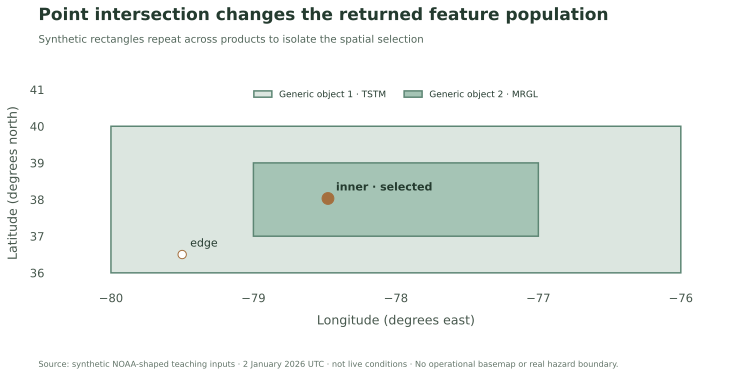

In [12]:
from matplotlib.patches import Polygon

fig, ax = plt.subplots(figsize=(10.8, 5.5))
for row, color in zip(polygons.itertuples(), ["#DCE6E0", "#A5C4B5"], strict=True):
    ring = json.loads(row.geometry_json)["coordinates"][0][0]
    ax.add_patch(
        Polygon(
            ring,
            facecolor=color,
            edgecolor="#5D8674",
            linewidth=1.5,
            label=f"Generic object {int(row.object_id)} · {row.label}",
        )
    )
for r in sites.itertuples():
    ax.scatter(
        r.longitude,
        r.latitude,
        s=140 if r.site == SITE else 70,
        facecolors="#A46F3E" if r.site == SITE else "white",
        edgecolors="#A46F3E",
        zorder=4,
    )
    ax.annotate(
        r.site + (" · selected" if r.site == SITE else ""),
        (r.longitude, r.latitude),
        xytext=(8, 8),
        textcoords="offset points",
        weight="bold" if r.site == SITE else "normal",
    )
ax.set(
    xlabel="Longitude (degrees east)",
    ylabel="Latitude (degrees north)",
    xlim=(-80.4, -75.6),
    ylim=(35.7, 41.2),
)
ax.legend(loc="upper center", fontsize=9, ncols=2)
finish(
    fig,
    "Point intersection changes the returned feature population",
    "Synthetic rectangles repeat across products to isolate the spatial selection",
    PROVENANCE + " · No operational basemap or real hazard boundary.",
    name=f"product-intersections-{SITE}",
)

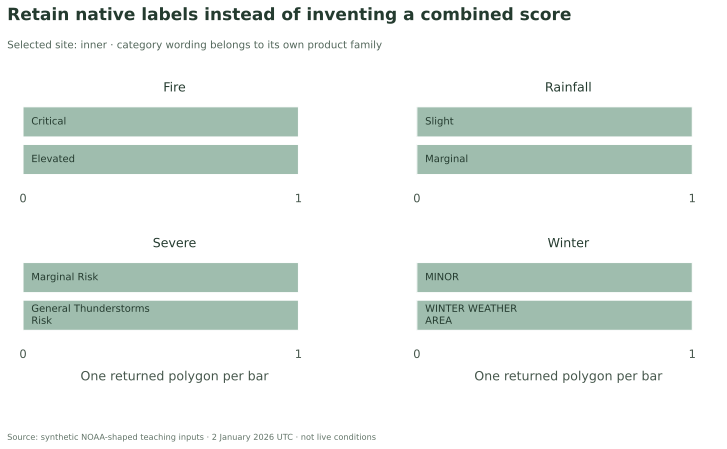

In [13]:
fig, axes = plt.subplots(2, 2, figsize=(11, 6.6))
for ax, (family, rows) in zip(axes.flat, selected.groupby("family", sort=True), strict=True):
    rows = rows.sort_values("object_id")
    ax.barh(range(len(rows)), np.ones(len(rows)), color="#9FBDAE", height=0.8)
    for i, r in enumerate(rows.itertuples()):
        label = r.native_label.replace("General Thunderstorms Risk", "General Thunderstorms\nRisk").replace(
            "WINTER WEATHER AREA", "WINTER WEATHER\nAREA"
        )
        ax.text(0.03, i, label, va="center", fontsize=10)
    ax.set(
        title=family.capitalize(),
        yticks=[],
        xticks=[0, 1],
        xlim=(0, 1.1),
        ylim=(-0.65, 1.65),
        xlabel="One returned polygon per bar",
    )
fig.subplots_adjust(hspace=0.8)
for ax in axes[0]:
    ax.set_xlabel("")
finish(
    fig,
    "Retain native labels instead of inventing a combined score",
    f"Selected site: {SITE} · category wording belongs to its own product family",
    PROVENANCE,
    name=f"product-vocabularies-{SITE}",
)

### Reconcile interfaces, populations and typed interpretation

The generic severe-layer object IDs must agree with the typed severe reader. Each
named/positional pair must agree on all business fields, and every point result must
belong to its complete layer. These checks test parsing and selection in the local
scenario; they do not validate operational polygons, probability calibration or alert
issuance. Unsupported services and the other catalog surfaces remain outside this
notebook's coverage rather than being silently removed from the catalog.

In [14]:
%%sql checks <<
SELECT 'layers interface equivalence' AS check_name,NOT EXISTS((SELECT * EXCLUDE(source_url,fetched_at) FROM layers EXCEPT SELECT * EXCLUDE(source_url,fetched_at) FROM layers_compat) UNION ALL (SELECT * EXCLUDE(source_url,fetched_at) FROM layers_compat EXCEPT SELECT * EXCLUDE(source_url,fetched_at) FROM layers)) AS passed
UNION ALL SELECT 'fields interface equivalence' AS check_name,NOT EXISTS((SELECT * EXCLUDE(source_url,fetched_at) FROM fields EXCEPT SELECT * EXCLUDE(source_url,fetched_at) FROM fields_compat) UNION ALL (SELECT * EXCLUDE(source_url,fetched_at) FROM fields_compat EXCEPT SELECT * EXCLUDE(source_url,fetched_at) FROM fields)) AS passed
UNION ALL SELECT 'generic interface equivalence' AS check_name,NOT EXISTS((SELECT * EXCLUDE(source_url,fetched_at) FROM generic EXCEPT SELECT * EXCLUDE(source_url,fetched_at) FROM generic_compat) UNION ALL (SELECT * EXCLUDE(source_url,fetched_at) FROM generic_compat EXCEPT SELECT * EXCLUDE(source_url,fetched_at) FROM generic)) AS passed
UNION ALL SELECT 'generic_at interface equivalence' AS check_name,NOT EXISTS((SELECT * EXCLUDE(source_url,fetched_at) FROM generic_at EXCEPT SELECT * EXCLUDE(source_url,fetched_at) FROM generic_at_compat) UNION ALL (SELECT * EXCLUDE(source_url,fetched_at) FROM generic_at_compat EXCEPT SELECT * EXCLUDE(source_url,fetched_at) FROM generic_at)) AS passed
UNION ALL SELECT 'severe_at interface equivalence' AS check_name,NOT EXISTS((SELECT * EXCLUDE(source_url,fetched_at) FROM severe_at EXCEPT SELECT * EXCLUDE(source_url,fetched_at) FROM severe_compat) UNION ALL (SELECT * EXCLUDE(source_url,fetched_at) FROM severe_compat EXCEPT SELECT * EXCLUDE(source_url,fetched_at) FROM severe_at)) AS passed
UNION ALL SELECT 'fire_at interface equivalence' AS check_name,NOT EXISTS((SELECT * EXCLUDE(source_url,fetched_at) FROM fire_at EXCEPT SELECT * EXCLUDE(source_url,fetched_at) FROM fire_compat) UNION ALL (SELECT * EXCLUDE(source_url,fetched_at) FROM fire_compat EXCEPT SELECT * EXCLUDE(source_url,fetched_at) FROM fire_at)) AS passed
UNION ALL SELECT 'rainfall_at interface equivalence' AS check_name,NOT EXISTS((SELECT * EXCLUDE(source_url,fetched_at) FROM rainfall_at EXCEPT SELECT * EXCLUDE(source_url,fetched_at) FROM rainfall_compat) UNION ALL (SELECT * EXCLUDE(source_url,fetched_at) FROM rainfall_compat EXCEPT SELECT * EXCLUDE(source_url,fetched_at) FROM rainfall_at)) AS passed
UNION ALL SELECT 'winter_at interface equivalence' AS check_name,NOT EXISTS((SELECT * EXCLUDE(source_url,fetched_at) FROM winter_at EXCEPT SELECT * EXCLUDE(source_url,fetched_at) FROM winter_compat) UNION ALL (SELECT * EXCLUDE(source_url,fetched_at) FROM winter_compat EXCEPT SELECT * EXCLUDE(source_url,fetched_at) FROM winter_at)) AS passed
UNION ALL SELECT 'discovered feature layer',count(*)=1 AND min(layer_id)=101 AND min(reader)='map_features' FROM layers
UNION ALL SELECT 'generic and typed severe identities',NOT EXISTS((SELECT site,object_id FROM generic_at EXCEPT SELECT site,object_id FROM severe_at) UNION ALL (SELECT site,object_id FROM severe_at EXCEPT SELECT site,object_id FROM generic_at))
UNION ALL SELECT 'fixed intersection population',count(*)=12 AND count(DISTINCT(family,site,object_id))=12 FROM intersections
UNION ALL SELECT 'selected population',count(*)=CASE WHEN '{{SITE}}'='inner' THEN 8 ELSE 4 END FROM selected
UNION ALL SELECT 'native validity stays one day',bool_and(date_diff('hour',valid_from,valid_to)=24) FROM intersections
UNION ALL SELECT 'missing probabilities not zero',(SELECT count(probability_pct)=0 FROM severe_full) AND (SELECT count(probability_pct)=0 FROM fire_full)
UNION ALL SELECT 'missing fire issue time retained',count(issued_at)=0 FROM fire_full
UNION ALL SELECT 'rainfall explanation retained',count(*)=2 AND count(risk_description)=2 FROM rainfall_full
UNION ALL SELECT 'winter component retained',count(*)=2 AND min(component)='overall' FROM winter_full
UNION ALL SELECT 'severe point IDs belong to source',NOT EXISTS(SELECT object_id FROM severe_at EXCEPT SELECT object_id FROM severe_full)
UNION ALL SELECT 'fire point IDs belong to source',NOT EXISTS(SELECT object_id FROM fire_at EXCEPT SELECT object_id FROM fire_full)
UNION ALL SELECT 'rainfall point IDs belong to source',NOT EXISTS(SELECT object_id FROM rainfall_at EXCEPT SELECT object_id FROM rainfall_full)
UNION ALL SELECT 'winter point IDs belong to source',NOT EXISTS(SELECT object_id FROM winter_at EXCEPT SELECT object_id FROM winter_full);

In [15]:
assert len(checks) == 21 and checks.passed.all()
requests = source.audit()
display(checks)
Path("artifacts/spatial-audit.json").write_text(
    json.dumps(
        {
            "parameter": SITE,
            "selected": selected.to_dict("records"),
            "intersections": con.execute("SELECT * FROM intersections ORDER BY family,site,object_id")
            .df()
            .to_dict("records"),
            "polygons": polygons.to_dict("records"),
            "checks": checks.to_dict("records"),
            "requests": requests,
        },
        indent=2,
        default=str,
    )
    + "\n"
)
prose(
    f"All **{len(checks)} SQL checks** pass across **{len(requests)} bounded local requests**. Generic discovery and typed readers agree on identities; all labels keep their own product meanings."
)

,check_name,passed
0,layers interface equivalence,True
1,fields interface equivalence,True
2,generic interface equivalence,True
3,generic_at interface equivalence,True
4,severe_at interface equivalence,True
5,fire_at interface equivalence,True
6,rainfall_at interface equivalence,True
7,winter_at interface equivalence,True
8,discovered feature layer,True
9,generic and typed severe identities,True


All **21 SQL checks** pass across **29 bounded local requests**. Generic discovery and typed readers agree on identities; all labels keep their own product meanings.

### Experiment: move the display selection to the edge

Change **SITE from "inner" to "edge"**. Each family contributes one feature instead
of two, while the complete polygon documents, both-site retrieval and source timestamps
stay fixed. The category lists shrink because the point intersects fewer polygons;
there is no numerical combined score to increase or decrease. Restore "inner" afterward.

In [16]:
assert con.execute("SELECT name FROM duckdb_secrets()").fetchall() == []
session.close()
source.close()
plt.close("all")

<a href="https://query.farm/"><img src="https://raw.githubusercontent.com/Query-farm/vgi-example-notebooks/v0.1.1/assets/query-farm-strata-sun.svg" alt="Query.Farm — Strata Sun" width="252"></a>

[Query.Farm](https://query.farm/) · [VGI](https://query.farm/vgi/) · [Worker repository: vgi-nws](https://github.com/Query-farm/vgi-nws)